# Example in `R`
We have covered a lot of information by this point. Although this may give the impression that binary logistic regression is very complex, we will now see that its application is actually quite simple. This is, in part, due to the support of many familiar functions within `R`, making this a reasonably straightforward extension of the normal linear model. As we saw last semester, our generic modelling sequence will be `glm` $\rightarrow$ `summary` $\rightarrow$ `Anova` $\rightarrow$ `emmeans`, with plots produced by the default routines and `effects` as needed.

## Packages
We will first load all the packages we need. Because some of these are a bit "chatty" when we load them, we suppress all the startup messages using the `suppressMessages()` function.

In [1]:
library('datarium')
library('gridExtra')
suppressMessages(library('effects'))
suppressMessages(library('car'))
suppressMessages(library('emmeans'))

## The `infections` Dataset
... Our basic model for this analysis will then involve the following variables:

- **count**: 

These variables are not labelled very clearly, particularly the factor levels, so we will adjust these so that the `R` output is more intuitive. We will therefore subset and relabel the variables we need using

In [2]:
data('infections')


head(infections)

  id treatment age count
1  1   placebo  32     4
2  2   placebo  52     5
3  3   placebo  36     4
4  4   placebo  55    12
5  5   placebo  58     7
6  6   placebo  22     5

We now have a new dataset called `cleveland` containing only the variables we need. Both `sex` and `cp` (renamed to `cpain`) now have more intuitive labels, with the baseline chest pain category set to *asymptomatic*. We can check the new structure using

In [3]:
str(infections)

'data.frame':	100 obs. of  4 variables:
 $ id       : int  1 2 3 4 5 6 7 8 9 10 ...
 $ treatment: Factor w/ 2 levels "placebo","treated": 1 1 1 1 1 1 1 1 1 1 ...
 $ age      : num  32 52 36 55 58 22 41 56 42 38 ...
 $ count    : int  4 5 4 12 7 5 8 8 5 2 ...


and can produce some basic summaries using

In [4]:
summary(infections)

       id           treatment       age            count      
 Min.   :  1.00   placebo:50   Min.   :20.00   Min.   : 1.00  
 1st Qu.: 25.75   treated:50   1st Qu.:30.00   1st Qu.: 2.00  
 Median : 50.50                Median :39.00   Median : 3.00  
 Mean   : 50.50                Mean   :39.99   Mean   : 3.82  
 3rd Qu.: 75.25                3rd Qu.:50.00   3rd Qu.: 5.00  
 Max.   :100.00                Max.   :60.00   Max.   :12.00  

## Fitting the Model
We now turn to fitting the model in `R`. We start with a formal description before seeing how to express this model in code.


### Model Description
..

### Specifying the Model in `R`
Next, we specify the model in `R`. Before doing so, we should check how `treatment` is coded.

In [5]:
contrasts(infections$treatment)

        treated
placebo       0
treated       1

So, sensibly, `placebo` is the baseline category.

In order to fit the model, we use the `glm` function included with base `R`. ...

In [6]:
mod <- glm(count ~ age + treatment,  # model formula
           family=poisson(link=log), # Poisson family w/log link
           data=infections)          # dataset

Much like the `lm` function, we can then call `summary()` on the model object to print a table of the estimates, hypothesis tests and other details about the model fit

In [7]:
summary(mod)


Call:
glm(formula = count ~ age + treatment, family = poisson(link = log), 
    data = infections)

Coefficients:
                  Estimate Std. Error z value Pr(>|z|)    
(Intercept)       0.668071   0.210448   3.175   0.0015 ** 
age               0.023955   0.004568   5.244 1.57e-07 ***
treatmenttreated -0.831754   0.112840  -7.371 1.69e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 171.273  on 99  degrees of freedom
Residual deviance:  75.838  on 97  degrees of freedom
AIC: 383.19

Number of Fisher Scoring iterations: 4


### Interpreting the Estimates
...

In [8]:
beta.0 <- coef(mod)[1]
exp(beta.0)

(Intercept) 
    1.95047 

As such, the expected average count of infections over 1 year is 1.95 for someone taking the placebo treatment who is aged 0. Clearly, this is not particularly useful. We could make this more useful by centering `age`

In [33]:
infections$c.age <- infections$age - mean(infections$age) # mean-centered

mod <- glm(count ~ c.age + treatment,  # model formula
           family=poisson(link=log),   # Poisson family w/log link
           data=infections)            # dataset

beta.0 <- coef(mod)[1]
exp(beta.0)

(Intercept) 
   5.083579 

So, now we have a baseline of around 5 infections for someone in the placebo group of average age. For this dataset, this is an age of

In [34]:
mean(infections$age)

[1] 39.99

so we can say a predicted average number of infections of 5 for someone aged 40 who was taking the placebo. The marginal distribution assumed by the model at this baseline is therefore

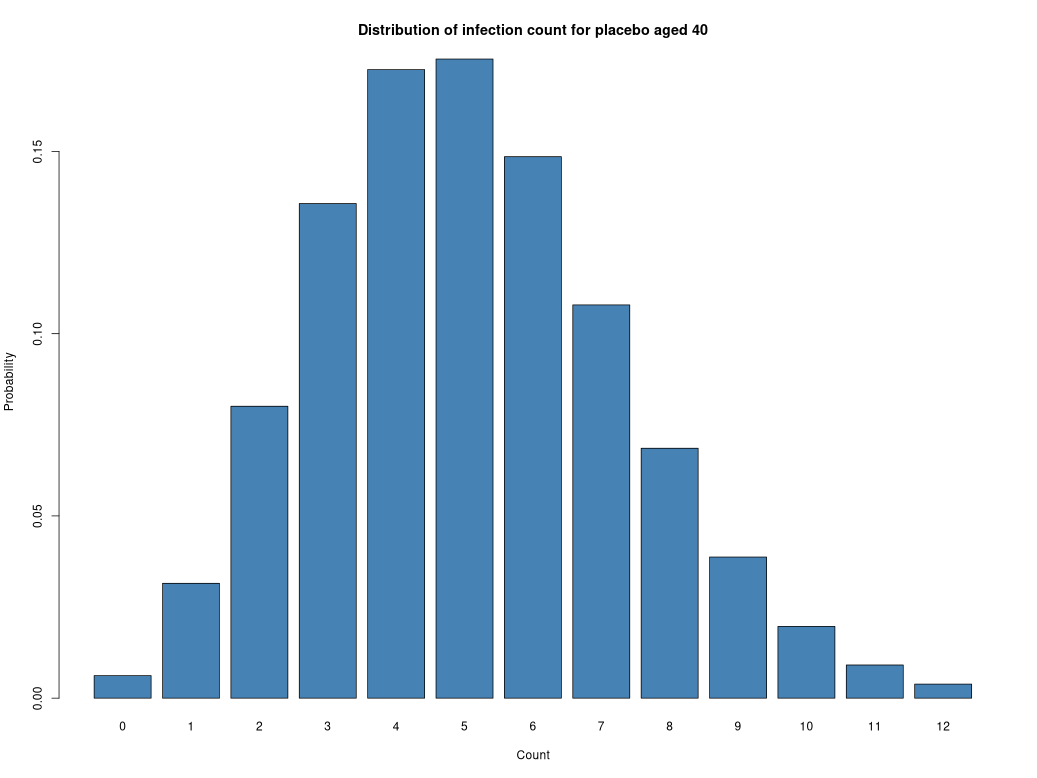

In [35]:
x <- 0:max(infections$count)
p <- dpois(x, lambda=exp(beta.0))

barplot(p, names.arg=x, col="steelblue", 
        xlab = "Count", ylab = "Probability",
        main = "Distribution of infection count for placebo aged 40")

In terms of the remaining effects, it is more helpful to undo the log and interpret the values as *count ratios*. We can do this using

In [36]:
beta <- coef(mod)[2:3]
exp(beta)

           c.age treatmenttreated 
        1.024244         0.435285 

We could also turn these into percentage changes in the counts using

In [37]:
(exp(beta) - 1)*100

           c.age treatmenttreated 
        2.424383       -56.471504 

...


The `effects` package can be invaluable for helping make sense of these various effects. We have previously used this package to create plots, which we will also do further below. However, for GLMs, looking at the actual values returned prior to plotting can be very helpful. In general, `effects` will automatically try to express the results on the most intuitive scale. As such, the default for logistic regression is *probability*. If we extract the effects, we can therefore view the probabilities using

In [38]:
mod.effs <- allEffects(mod,fixed.predictors=list(given.values="equal"))
print(mod.effs)

 model: count ~ c.age + treatment

 c.age effect
c.age
     -20      -10     0.01       10       20 
2.077252 2.639507 3.354752 4.261770 5.415313 

 treatment effect
treatment
 placebo  treated 
5.083579 2.212806 


We can see here that an awkward consequence of mean centering `age` is that we have to use the mean centered values for interpretation. For each value reported we need to treat it as *relative* to the mean of 40. So `-20` corresponds to age 20, `-10` to age 30, `10` to age 50 and so on.

## Model Diagnostics
As mentioned in the previous section, there are assumptions that we need to check prior to inference. The `glm()` function does have a standard set of plots that can be produced by calling `plot()` on the model object.

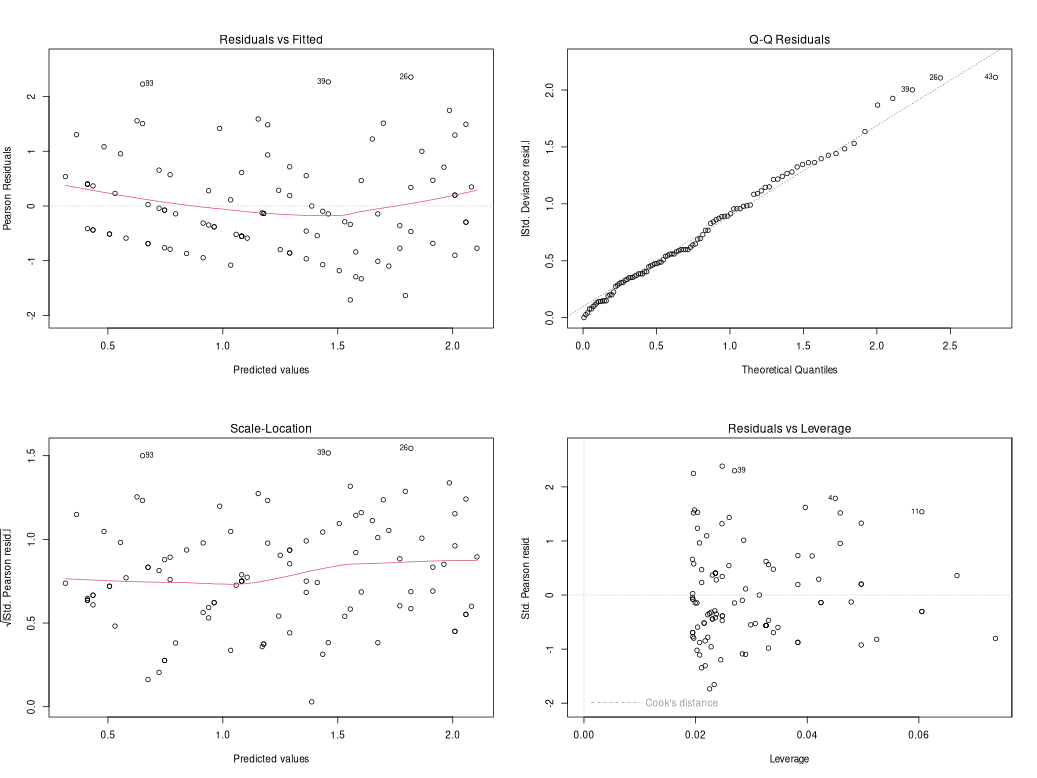

In [39]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

...

### Plotting the Model Fit
A much more important aspect of binary linear regression is assessing the quality of the model fit. This needs to be judged on the scale of the link function, because this is where the standard linear regression equation is found. Any evidence that a simple straight line is insufficient will require transforms or additional non-linear modelling.

We can again make use of the `effects` package to assess the model fit

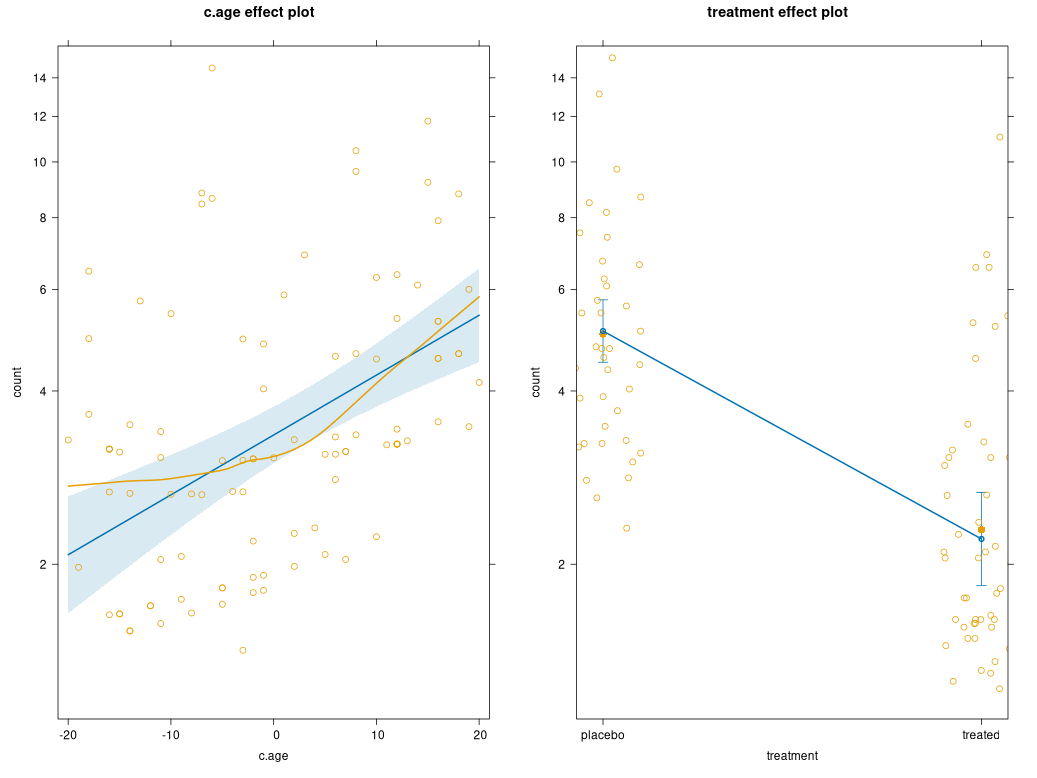

In [40]:
mod.effs <- allEffects(mod, 
                       fixed.predictors=list(given.values="equal"), 
                       partial.residuals=TRUE)
plot(mod.effs)

The most important aspect here is the argument `partial.residuals=TRUE`, which will plot both the residuals and an additional LOESS smoothing line tracing the average pattern through the residuals. This is shown in yellow and should roughly agree with the shape of the model fit shown in blue. This is more relevant for continuous predictors than categorical predictors. As such, the model fit for `age` should be our key focus here. We can isolate this using 

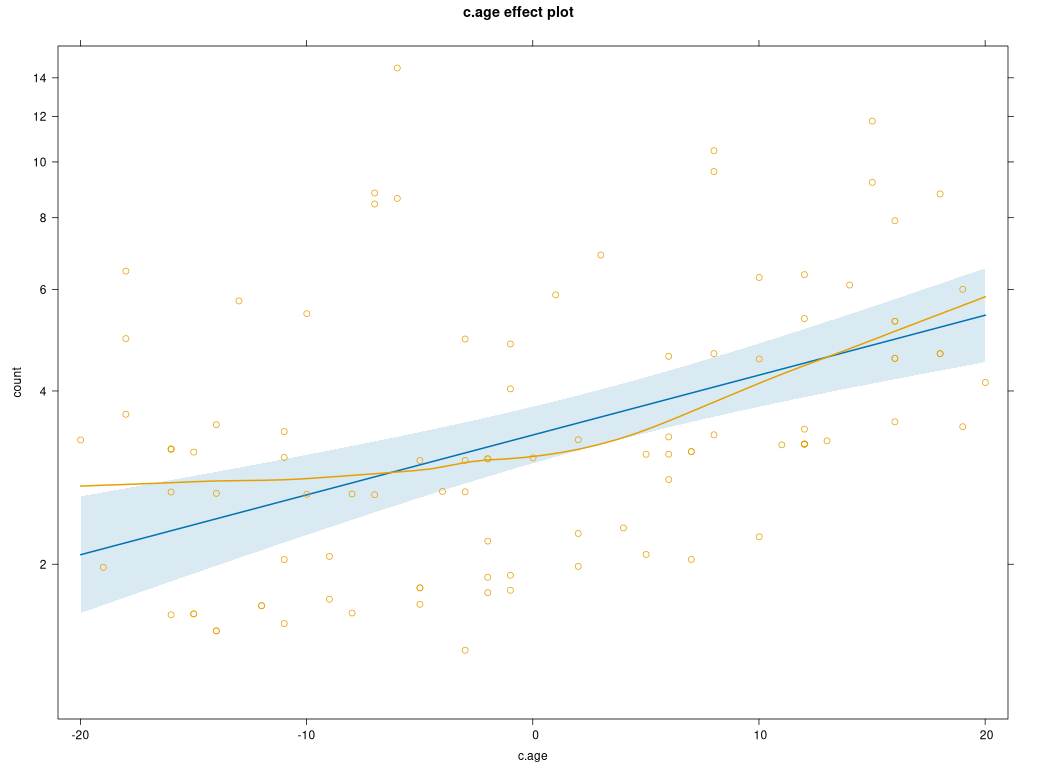

In [52]:
age.eff <- effect('c.age', mod, 
                  fixed.predictors=list(given.values="equal"), 
                  partial.residuals=TRUE)
plot(age.eff)

We can see here that the LOESS line shows ...

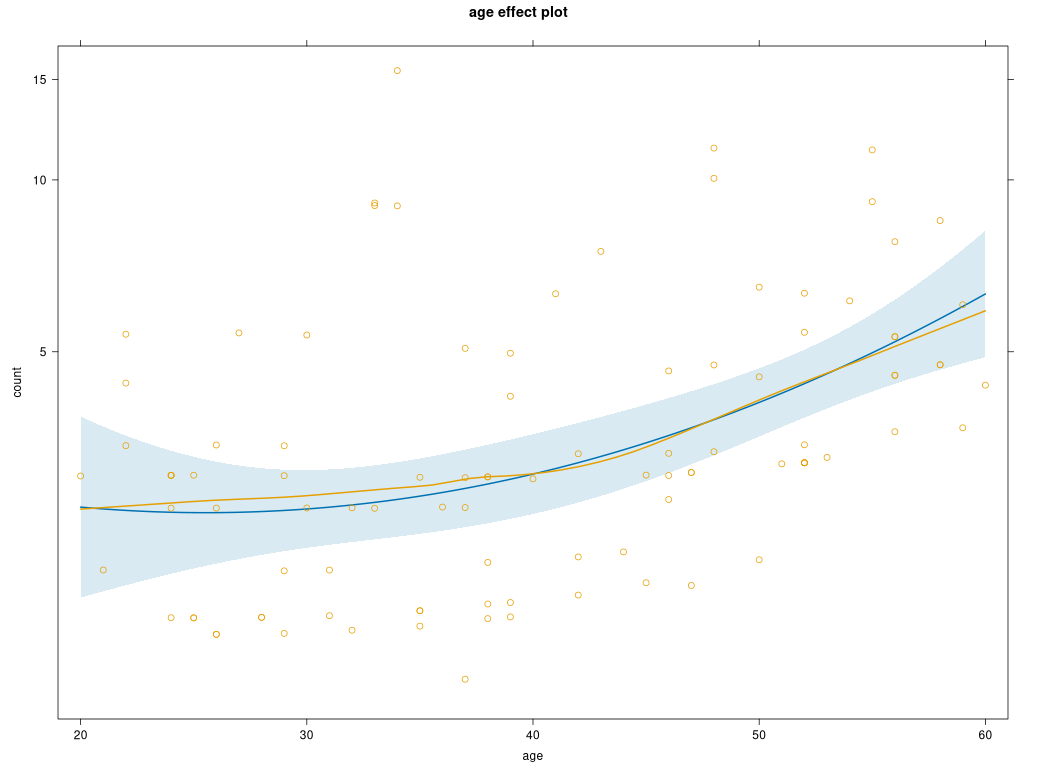

In [54]:
mod.quad <- glm(count ~ poly(age,2) + treatment, 
                family=poisson(link=log),         
                data=infections)                      

qage.eff <- effect('poly(age,2)', mod.quad,
                   fixed.predictors=list(given.values="equal"), 
                   partial.residuals=TRUE)
plot(qage.eff)

#### Options for Scaling Effects Displays
The `effects` package has several options for how the plots are scaled, depending upon how you want to interpret them. These are compared below in terms of the `age` effect from our original model.


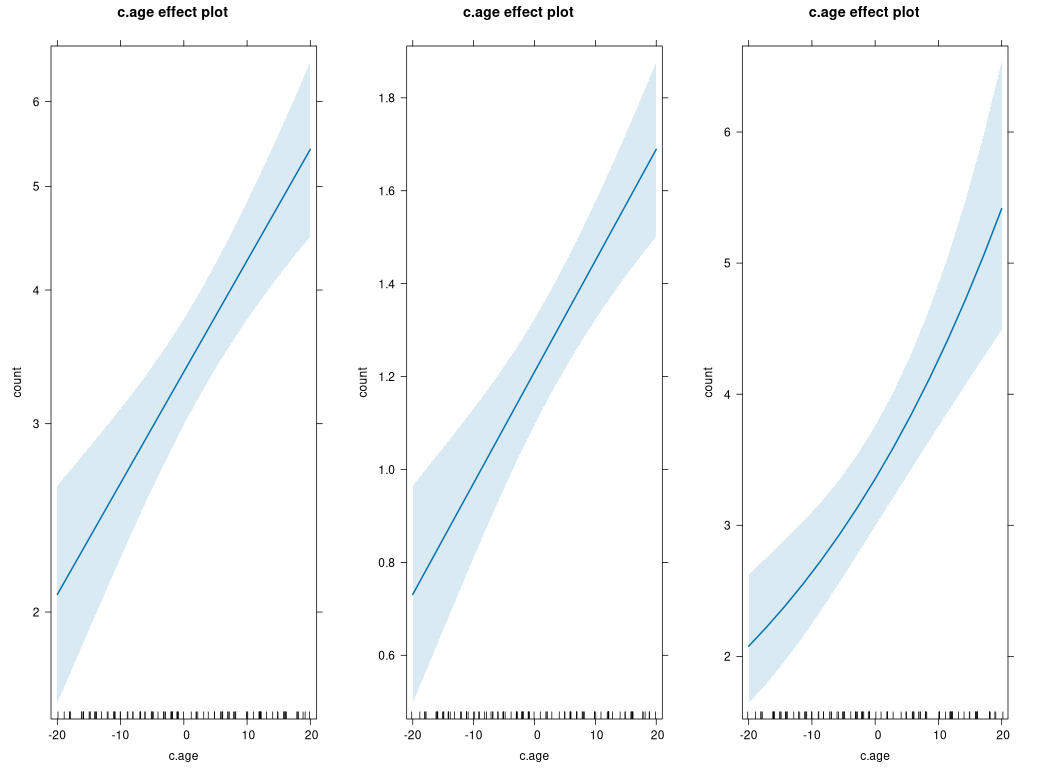

In [ ]:
# extract age effect
age.eff <- effect('c.age',mod,fixed.predictors=list(given.values="equal"))

# compare plots
p1 <- plot(age.eff, axes=list(y=list(type="rescale" ))) # link w/count labels
p2 <- plot(age.eff, axes=list(y=list(type="link"    ))) # link 
p3 <- plot(age.eff, axes=list(y=list(type="response"))) # count

grid.arrange(p1, p2, p3, ncol=3)

The left plot is the default and uses the option `type="rescale"`. This will draw the $y$-axis using the log scale so that the fit is linear. However, to make this easier to interpret, count labels will be written instead. 

The middle plot uses the option `type="link"`, and will do exactly the same as above, but *without* the count labels. As such, this is a direct plot of the model fit on the scale of the link function, meaning the $y$-axis is given in units of the log counts.

The right plot uses the option `type="response"`, and will draw the model fit on the count scale. This means that the exponential curve typified by the log link will be visible.

## Inference on the Effects
Once we are happy that there are no extreme values and that the model fit is acceptable, we can turn to inference. This is performed using the Wald tests on the coefficients, as well as the omnibus tests that typify an Analysis of Deviance. We will illustrate both below.

### Wald Tests
The tests reported on the raw model coefficients are examples of asymptotic Wald tests on the scale of the log-odds. Looking at the summary table again

In [56]:
summary(mod)


Call:
glm(formula = count ~ c.age + treatment, family = poisson(link = log), 
    data = infections)

Coefficients:
                  Estimate Std. Error z value Pr(>|z|)    
(Intercept)       1.626016   0.063688  25.531  < 2e-16 ***
c.age             0.023955   0.004568   5.244 1.57e-07 ***
treatmenttreated -0.831754   0.112840  -7.371 1.69e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 171.273  on 99  degrees of freedom
Residual deviance:  75.838  on 97  degrees of freedom
AIC: 383.19

Number of Fisher Scoring iterations: 4


we can see the estimates themselves, the standard errors, the $z$-statistics and the $p$-values. As mentioned previously, the null hypotheses for each of these tests concern an effect of 0 on the scale of the log-odds. For the intercept, this is a test of a 50% probability of heart disease when all predictors are 0. In the current example, this not particularly useful. For the slopes, this is a test that the probability of heart disease does not change with each predictor. So, a test of no relationship with `age`, no difference in probability between male and female, and no difference in probability between asymptomatic chest pains and each of the remaining categories. 

The $z$-statistics are calculated by dividing the estimates by their standard errors. For example, in the case of `age`, we have

In [20]:
est <- 0.06661
se  <- 0.01767
z   <- est/se
print(z)

[1] 3.769666


which agrees with what we see in the table. Remember that, asymptotically, the standard error is assumed known thanks to the properties of maximum likelihood estimation. As such, asymptotically, the statistic follows a standard normal distribution under the null and the two-tailed $p$-value is given by

In [21]:
2*pnorm(z, lower.tail=FALSE)

[1] 0.0001634661

which, again, agrees with the table.

For this dataset $n = 303$, which is neither small nor especially large. On this basis, we would probably feel reasonably comfortable using asymptotic approximations, but should remain cautious. None of the $p$-values are particularly marginal, which provides further comfort, though is no guarantees of their accuracy. Luckily for logistic regression we can visualise and examine these effects and their uncertainty on the intuitive scale of probability, meaning we are less beholden to hypothesis tests to aid interpreting these findings.

### Omnibus Tests
As well as tests on the individual coefficients, we can also perform omnibus tests on groups of coefficients associated with individual effects. For the current example, the most obvious use case is calculating a main effect of `cpain`. We can do this by using the `Anova()` function from `car`, as we have done previously.

In [22]:
Anova(mod)

Analysis of Deviance Table (Type II tests)

Response: disease
      LR Chisq Df Pr(>Chisq)    
age     15.428  1  8.573e-05 ***
sex     28.597  1  8.911e-08 ***
cpain   78.434  3  < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Notice that these are labelled as `Type II tests` and so the same testing logic we saw last semester applies to GLMs. Here, these tests are based on model comparisons using the *deviance*, which we can demonstrate by performing explicit model comparisons using the built-in `anova()` function. For instance, to test the effect of `cpain` we can specific a null model that does not contain `cpain` and a full model that does contain `cpain`.

In [23]:
mod.null <- update(mod, disease ~ age + sex        )
mod.full <- update(mod, disease ~ age + sex + cpain)

We can then compare these using the `anova` function

In [24]:
anova(mod.null,mod.full)

Analysis of Deviance Table

Model 1: disease ~ age + sex
Model 2: disease ~ age + sex + cpain
  Resid. Df Resid. Dev Df Deviance  Pr(>Chi)    
1       300     372.31                          
2       297     293.87  3   78.434 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Notice that the `Df`, `Deviance` and $p$-value are all identical to the table from `Anova`. 

We can also use the `anova()` function as a more general tool for model comparisons. For instance, in deciding whether a quadratic effect of `age` is necessary, we could use

In [25]:
mod.null <- update(mod, disease ~ age         + sex + cpain)
mod.full <- update(mod, disease ~ poly(age,2) + sex + cpain)

anova(mod.null, mod.full)

Analysis of Deviance Table

Model 1: disease ~ age + sex + cpain
Model 2: disease ~ poly(age, 2) + sex + cpain
  Resid. Df Resid. Dev Df Deviance Pr(>Chi)
1       297     293.87                     
2       296     293.03  1  0.83784     0.36

Alternatively, both AIC and BIC can be used for this purpose

In [26]:
AIC(mod.null, mod.full)

         df      AIC
mod.null  6 305.8720
mod.full  7 307.0342

In [27]:
BIC(mod.null, mod.full)

         df      BIC
mod.null  6 328.1544
mod.full  7 333.0303

recalling the interpretive cut-offs established in the ANOVA workshop last semester.

### Follow-up Tests
As a final inferential step, we can perform follow-up tests using the `emmeans` package, in much the same way we saw it used last semester.

In [28]:
emm <- emmeans(mod, pairwise ~ cpain, adjust='holm')
print(emm$contrasts)

 contrast     estimate    SE  df z.ratio p.value
 asymp - aAng    2.526 0.445 Inf   5.679 <0.0001
 asymp - nAng    2.377 0.354 Inf   6.710 <0.0001
 asymp - tAng    2.273 0.532 Inf   4.269 <0.0001
 aAng - nAng    -0.149 0.480 Inf  -0.310  1.0000
 aAng - tAng    -0.253 0.618 Inf  -0.410  1.0000
 nAng - tAng    -0.104 0.556 Inf  -0.188  1.0000

Results are averaged over the levels of: sex 
Results are given on the log odds ratio (not the response) scale. 
P value adjustment: holm method for 6 tests 


Notice that the first 3 tests are identical to the tests on the coefficients from the summary table, as we would expect given the dummy variable coding. The remaining tests concern contrasts of the coefficients used to derive the remaining comparisons between the levels of `cpain`. As we can see, there is clear evidence that the asymptomatic individuals are different from the remaining chest pain categories in terms of their log-odds of having heart disease. 

From the effects plots earlier, we can see that those who are asymptomatic have a much higher probability of having heart disease than those with existing chest pains. This may seem unintuitive at first, however, those with existing chest pains are likely already receiving treatment that has reduced their probability of having the arterial wall thickening used as the metric of heart disease in this study. However, those with no symptoms may not have sought treatment and thus may have untreated heart disease that has not yet been identified. This would explain the probability being much higher in those with no symptoms.

We can also get to those probabilities by looking at the actual marginal means produced by `emmeans`

In [29]:
emm$emmeans

 cpain emmean    SE  df asymp.LCL asymp.UCL
 asymp  0.679 0.206 Inf     0.275     1.083
 aAng  -1.846 0.405 Inf    -2.640    -1.052
 nAng  -1.698 0.301 Inf    -2.288    -1.107
 tAng  -1.593 0.502 Inf    -2.577    -0.609

Results are averaged over the levels of: sex 
Results are given on the logit (not the response) scale. 
Confidence level used: 0.95 

These are on the scale of the log-odds, so we can convert them to probability using

In [30]:
plogis(summary(emm$emmeans)$emmean)

[1] 0.6635848 0.1362999 0.1547714 0.1689157

which agrees with the probabilities extracted using the `effects` package. However, as noted earlier, this is only true when we request *unweighted* means from `effects`, rather than the default.


## Model Predictions
As a final step, we can also take then model beyond inference into the world of *prediction*. For instance, we can pass a new data frame to the `predict()` function, where the values of each variable are fixed to those we want predictions for. As an example, to compare the effect of `sex` in asymptomatic patients at age 80 and age 50, we could use

In [31]:
sim.data <- data.frame('age'   = c(80,      80,     50,     50      ), 
                       'sex'   = c('male', 'female','male', 'female'), 
                       'cpain' = c('asymp','asymp', 'asymp','asymp' ))

plogis(predict(mod,sim.data))

        1         2         3         4 
0.9623729 0.8208652 0.7761481 0.3831737 

As such, according to our model, there is substantial increased risk of heart disease in asymptomatic individuals if they are male, particularly at a younger age. Being 50 years old carries limited probability of 38% if someone is female, but this jumps dramatically to 78% if they are male. Once people reach 80, the probability of heart disease is very high in both groups, but is considerably more certain in males (96%) than females (82%). Of course, this all depends upon the accuracy of our model.